# Aprendizaje geométrico con Christoffel–Darboux · cuaderno de experimentos
**Ruta de lectura:** §2 del documento base → 01–02 (álgebra y soporte); §5.2–5.3 → 03–06 (puntos y escenas); §5.4 → 07–10 (objetos); §5.5 → 11 (reconstrucción). La última tabla reúne las decisiones que permite tomar cada prueba.

**Cómo reproducir:** usa un entorno con Python ≥3.11, NumPy, SciPy, pandas, matplotlib, scikit-learn, threadpoolctl e IPython/Jupyter. Abre el cuaderno dentro del clon de point-field o instala ese clon con pip en el kernel. Sólo importamos sus generadores. No hacen falta notebook_tools, parches, resultados previos ni archivos auxiliares. Los modelos CD, la fase, el descriptor, la métrica, el lector OFF, el decoder y las métricas de recuperación están implementados abajo. Para comparadores estándar se usan las implementaciones de scikit-learn.

**Protocolo docente nuevo.** No pretende producir las cifras de A8: el conjunto de formas, algunas fórmulas y el decoder cambian. La ejecución guardada usa el modo rápido. Reejecutar con más objetos mejora la precisión de las estimaciones; nunca convierte por sí solo un experimento exploratorio en confirmatorio.

In [10]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, hashlib, math, itertools, time, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import solve_triangular
from scipy.spatial.distance import cdist, pdist
from scipy.special import eval_legendre
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics import adjusted_rand_score as ARI, adjusted_mutual_info_score as AMI, silhouette_score, roc_auc_score
from sklearn.manifold import Isomap, trustworthiness
from sklearn.decomposition import PCA, KernelPCA
from threadpoolctl import threadpool_limits
threads=threadpool_limits(1)
repo=next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/pointfield').is_dir()),None)
if repo: sys.path.insert(0,str(repo/'src'))
from pointfield.datasets import make
from pointfield.objects import make_object_dataset
from pointfield.geometry.shapes2d import Annulus
MODE='rapido'  # 'amplio' para más muestras y semillas
SEM=20261119
REAL=False  # activar tras verificar rutas OFF
ROOTS={'ModelNet10':Path.home()/'Downloads/ModelNet10/ModelNet10','ModelNet40':Path.home()/'Downloads/ModelNet40'}
PART='validation'
TEST_CONGELADO=False
assert MODE in ('rapido','amplio') and PART in ('validation','test')
assert PART!='test' or TEST_CONGELADO
N=96 if MODE=='rapido' else 512
seeds=[100,101] if MODE=='rapido' else list(range(100,105))
out=Path.cwd()/'runs_desde_cero'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
out.mkdir(parents=True)
def guardar(nombre,df):
    df.to_csv(out/(nombre+'.csv'),index=False);return df
def figura(nombre):
    plt.tight_layout();plt.savefig(out/(nombre+'.png'),dpi=150,bbox_inches='tight');plt.show()
def rng(s):return np.random.default_rng(s)
def sem(*parts):return int.from_bytes(hashlib.sha256(str(parts).encode()).digest()[:4],'little')
import sklearn,scipy,matplotlib,pointfield
source=Path(pointfield.__file__).parent
config=dict(seed=SEM,modo=MODE,N=N,seeds=seeds,real=REAL,part=PART,roots={k:str(v) for k,v in ROOTS.items()},
            python=platform.python_version(),numpy=np.__version__,sklearn=sklearn.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__,
            generador_sha256=hashlib.sha256(b''.join(p.read_bytes() for p in sorted(source.rglob('*.py')))).hexdigest())
(out/'config.json').write_text(json.dumps(config,indent=2))
print('Configuración:',MODE,'| puntos por objeto:',N,'| salida:',out)

Configuración: rapido | puntos por objeto: 96 | salida: /home/icantu24/Documents/PEF-CD/point-field/notebooks/runs_desde_cero/20261119T212430343107Z


## 01 · Implementar CD y comprobarlo antes de agrupar nada
Cada fila de V evalúa todos los monomios de grado ≤ n en un punto. En dos dimensiones y grado dos son 1, x, y, x², xy, y². El producto de dos columnas sí puede tener grado cuatro: esa es una **entrada de M**, no una columna nueva de V. Para un polinomio con coeficientes a, el promedio de sus valores al cuadrado es aᵀMa; de ahí M=Vᵀdiag(w)V. La ponderación multinomial de las columnas hace que el producto interno de grado k sea (x·y)ᵏ.

Con A=M+εI, minimizar aᵀAa sujeto a aᵀv(z)=1 da a=A⁻¹v/q, q=vᵀA⁻¹v y Λ=1/q. Calculamos q con Cholesky: si A=LLᵀ, q es la norma cuadrada de L⁻¹v. No invertimos A.

,1,x,x²
0,1.0,-1.0,1.0
1,1.0,0.0,0.0
2,1.0,1.0,1.0


,0,1,2
0,1.000000,0.000000,0.666667
1,0.000000,0.666667,0.000000
2,0.666667,0.000000,0.666667


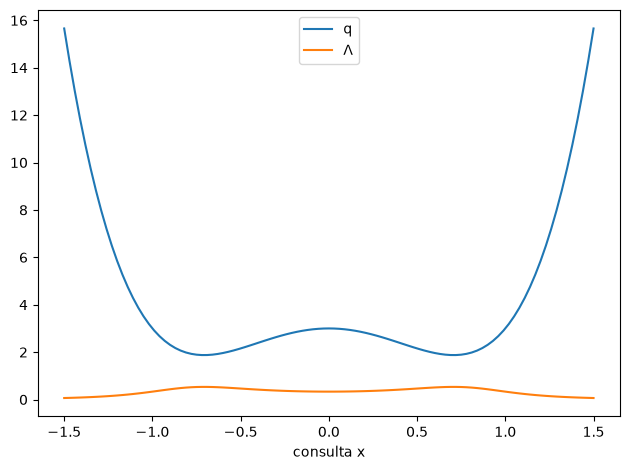

In [2]:
def normal(X):
    X=np.asarray(X,float); Y=X-X.mean(0); r=np.sqrt(np.mean(np.sum(Y*Y,axis=1)))
    if not np.isfinite(r) or r<=0:raise ValueError('Nube degenerada')
    return Y/r
def base(X,n):
    X=np.asarray(X,float); cols=[]
    for k in range(n+1):
        for t in itertools.combinations_with_replacement(range(X.shape[1]),k):
            mult=math.factorial(k)/math.prod(math.factorial(t.count(j)) for j in set(t))
            cols.append(np.sqrt(mult)*np.prod(X[:,list(t)],axis=1))
    return np.column_stack(cols)
def ajustar(X,n=2,reg=.01,w=None):
    V=base(X,n);w=np.ones(len(V)) if w is None else np.asarray(w,float)
    assert np.all(np.isfinite(w)) and np.all(w>=0) and w.sum()>0 and reg>=0
    M=V.T@((w/w.sum())[:,None]*V); eps=reg*np.trace(M)/len(M)
    return n,M,np.linalg.cholesky(M+eps*np.eye(len(M))),eps
def blanco(model,X):return solve_triangular(model[2],base(X,model[0]).T,lower=True).T
def score(model,X):return (blanco(model,X)**2).sum(1)
X=np.array([[-1.],[0.],[1.]])
m=ajustar(X,2,0);z=np.linspace(-1.5,1.5,101);q=score(m,z[:,None])
assert np.allclose(q,3-4.5*z**2+4.5*z**4) and np.isclose(score(m,X).mean(),3)
display(pd.DataFrame(base(X,2),columns=['1','x','x²']));display(pd.DataFrame(m[1]))
plt.plot(z,q,label='q');plt.plot(z,1/q,label='Λ');plt.legend();plt.xlabel('consulta x');figura('01_score')

## 02 · Primer benchmark 2D: ¿el score recupera el hueco?
En una corona, aceptar q≤τ estima una región; no asigna etiquetas de grupo. Ajustamos CD con una muestra, calibramos τ al 95 % con otra y medimos la cobertura en una tercera. En la misma cuadrícula, calculamos IoU contra el anillo conocido. Comparamos grados sin cambiar las consultas. Sobre la circunferencia exacta mostramos por qué N grande no garantiza rango completo.

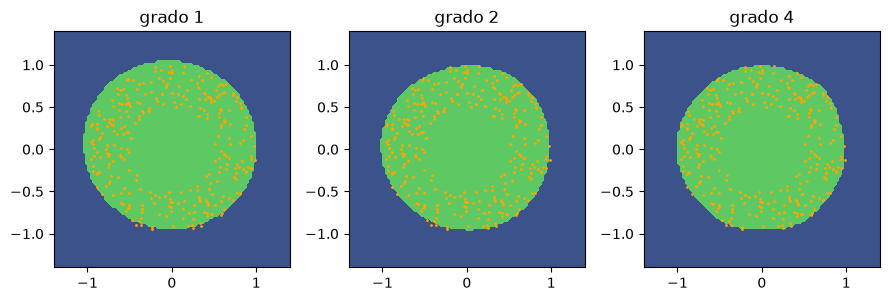

,grado,umbral,cobertura,IoU,AUROC
0,1,4.177245,0.960000,0.689457,0.859455
1,2,10.254232,0.943333,0.709276,0.950074
2,4,29.792379,0.940000,0.711577,0.952270


In [3]:
t=np.arange(256)*2*np.pi/256;circle=np.c_[np.cos(t),np.sin(t)]
m=ajustar(circle);assert np.linalg.matrix_rank(m[1])==5
eta=np.linalg.eigvalsh(m[1]);assert np.isclose(score(m,circle).mean(),sum(eta/(eta+m[3])))
shape=Annulus(.5,1);tr,cal,te=[shape.sample(300,seed=s) for s in (10,11,12)]
u=np.linspace(-1.4,1.4,101);xx,yy=np.meshgrid(u,u);grid=np.c_[xx.ravel(),yy.ravel()]
rad=np.linalg.norm(grid,axis=1);truth=(rad>=.5)&(rad<=1)
fig,axes=plt.subplots(1,3,figsize=(9,3));rows=[]
for ax,d in zip(axes,[1,2,4]):
    m=ajustar(tr,d);q=score(m,grid);tau=np.sort(score(m,cal))[math.ceil(.95*(1+len(cal)))-1];pred=q<=tau
    rows.append(dict(grado=d,umbral=tau,cobertura=np.mean(score(m,te)<=tau),IoU=(pred&truth).sum()/(pred|truth).sum(),AUROC=roc_auc_score(truth,-q)))
    ax.contourf(xx,yy,pred.reshape(xx.shape),levels=[-.5,.5,1.5]);ax.scatter(*tr.T,s=1,color='orange');ax.set(aspect='equal',title=f'grado {d}')
figura('02_soporte');display(guardar('02_soporte',pd.DataFrame(rows)))

## 03 · CD global como primer agrupador 2D
K-Means inicializa K grupos. Ajustamos un modelo CD por grupo y reasignamos cada punto al modelo con menor log q. Esto es una heurística, no una probabilidad de pertenencia: falta un modelo de mezcla normalizado. Si una reasignación vacía un grupo, conservamos la última partición válida. Fijamos desde aquí los mismos puntos, semillas y valores de K para las siguientes etapas.

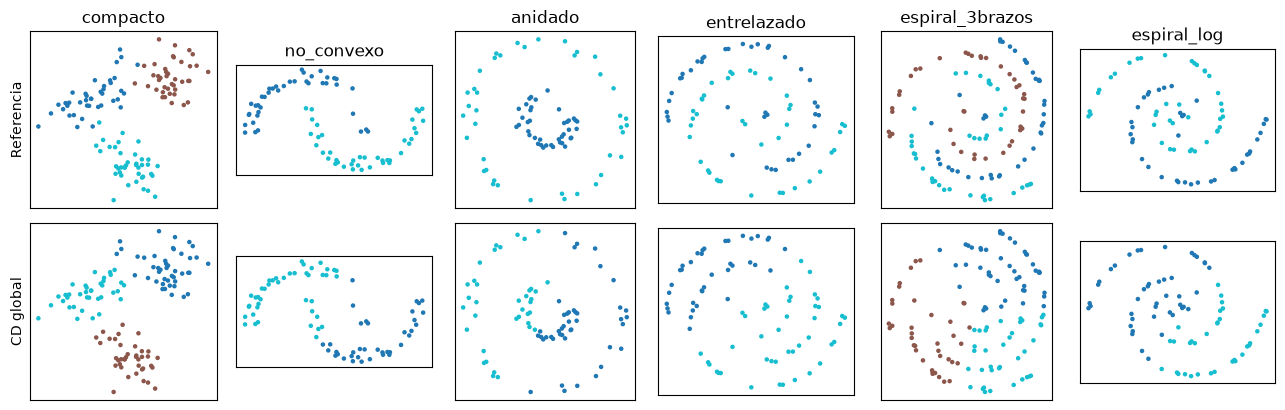

caso
anidado            0.006538
compacto           0.927301
entrelazado        0.003142
espiral_3brazos    0.036089
espiral_log        0.015511
no_convexo         0.371122
Name: ARI, dtype: float64

In [4]:
cases=['compacto','no_convexo','anidado','entrelazado','espiral_3brazos','espiral_log']
scenes={}
for s in seeds:
    for c in cases:
        ds=make(c,40 if MODE=='rapido' else 150,s);scenes[c,s]=(normal(ds.X),ds.y)
def global_cd(X,k):
    y=KMeans(k,n_init=10,random_state=0).fit_predict(X)
    for _ in range(20):
        q=np.column_stack([score(ajustar(X[y==j]),X) for j in range(k)])
        new=q.argmin(1)
        if len(np.unique(new))<k or np.array_equal(y,new):break
        y=new
    return y
records=[];partitions={}
def bench(name,fn,known):
    for (c,s),(X,y) in scenes.items():
        k=len(set(y));t=time.perf_counter();lab=fn(X,k if known else None)
        records.append(dict(caso=c,seed=s,modelo=name,K_dado=known,K_obtenido=len(set(lab)-{-1}),ARI=ARI(y,lab),ruido=np.mean(lab==-1),segundos=time.perf_counter()-t))
        partitions[c,s,name]=lab
def panel(names,file):
    fig,axs=plt.subplots(len(names),len(cases),figsize=(13,2.1*len(names)),squeeze=False)
    for i,n in enumerate(names):
        for ax,c in zip(axs[i],cases):
            X,y=scenes[c,seeds[0]];lab=y if n=='Referencia' else partitions[c,seeds[0],n]
            ax.scatter(*X.T,c=lab,cmap='tab10',s=5);ax.set(aspect='equal',xticks=[],yticks=[],title=c if i==0 else '')
            if ax is axs[i,0]:ax.set_ylabel(n)
    figura(file)
bench('CD global',global_cd,True);panel(['Referencia','CD global'],'03_global')
display(pd.DataFrame(records).groupby('caso').ARI.mean())

## 04 · Añadir comparadores; después, cambiar sólo la afinidad
K-Means minimiza dispersión; DBSCAN usa densidad sin K y aquí fija ε como el percentil 85 de la distancia al quinto vecino. El control espectral y CD local usan **exactamente los mismos vecinos** y el mismo particionador. Sólo cambian los pesos. Grado uno local está relacionado con Mahalanobis: una mejora no demostraría necesidad de polinomios de alto grado.

In [5]:
def grafos(X,k=10):
    D=cdist(X,X);np.fill_diagonal(D,np.inf);nb=np.argsort(D,axis=1)[:,:k]
    A=np.zeros_like(D);B=A.copy()
    for i,j in enumerate(nb):
        local=X[np.r_[i,j]]-X[i];q=score(ajustar(local,1),local)[1:]
        z=(q-np.median(q))/(np.median(abs(q-np.median(q)))+1e-9)
        A[i,j]=1;B[i,j]=np.exp(-np.clip(z*z/2,0,30))
    return np.maximum(A,A.T),np.maximum(B,B.T)
def spectral(A,k):return SpectralClustering(k,affinity='precomputed',random_state=0,n_init=10).fit_predict(A)
def db(X,_):
    D=cdist(X,X);eps=np.quantile(np.sort(D,axis=1)[:,5],.85)
    return DBSCAN(eps=max(eps,1e-12),min_samples=6).fit_predict(X)
bench('K-Means',lambda X,k:KMeans(k,n_init=10,random_state=0).fit_predict(X),True)
bench('DBSCAN',db,False);bench('Grafo binario',lambda X,k:spectral(grafos(X)[0],k),True)
bench('CD local',lambda X,k:spectral(grafos(X)[1],k),True)
display(pd.DataFrame(records).pivot_table(index='caso',columns='modelo',values='ARI'))

modelo,CD global,CD local,DBSCAN,Grafo binario,K-Means
caso,,,,,
anidado,0.006538,0.166852,0.721756,0.022980,0.006538
compacto,0.927301,0.950104,0.734821,0.950104,0.938695
entrelazado,0.003142,-0.006361,0.001300,0.020829,-0.000993
espiral_3brazos,0.036089,0.033559,0.000321,0.037481,0.036089
espiral_log,0.015511,0.015634,0.032385,0.027086,0.015447
no_convexo,0.371122,0.903794,0.859536,0.679202,0.371122


## 05 · Probar una mejora especializada: fase para espirales
Si r=a+bθ, entonces ψ=θ−r/b es constante en un brazo ideal. Probamos pendientes predefinidas y comparamos con pendiente cero por silueta, sin mirar etiquetas. Si la ganancia supera 0.20, usamos la fase; si no, conservamos CD local. Se usa K conocido. Este cambio de coordenadas no implementa el teorema de Szegő. En particular, la forma logarítmica no se ajusta explícitamente aquí.

modelo,CD + fase,CD global,CD local,DBSCAN,Grafo binario,K-Means
caso,,,,,,
anidado,0.167,0.007,0.167,0.722,0.023,0.007
compacto,0.950,0.927,0.950,0.735,0.950,0.939
entrelazado,0.495,0.003,-0.006,0.001,0.021,-0.001
espiral_3brazos,0.511,0.036,0.034,0.000,0.037,0.036
espiral_log,0.206,0.016,0.016,0.032,0.027,0.015
no_convexo,0.904,0.371,0.904,0.860,0.679,0.371


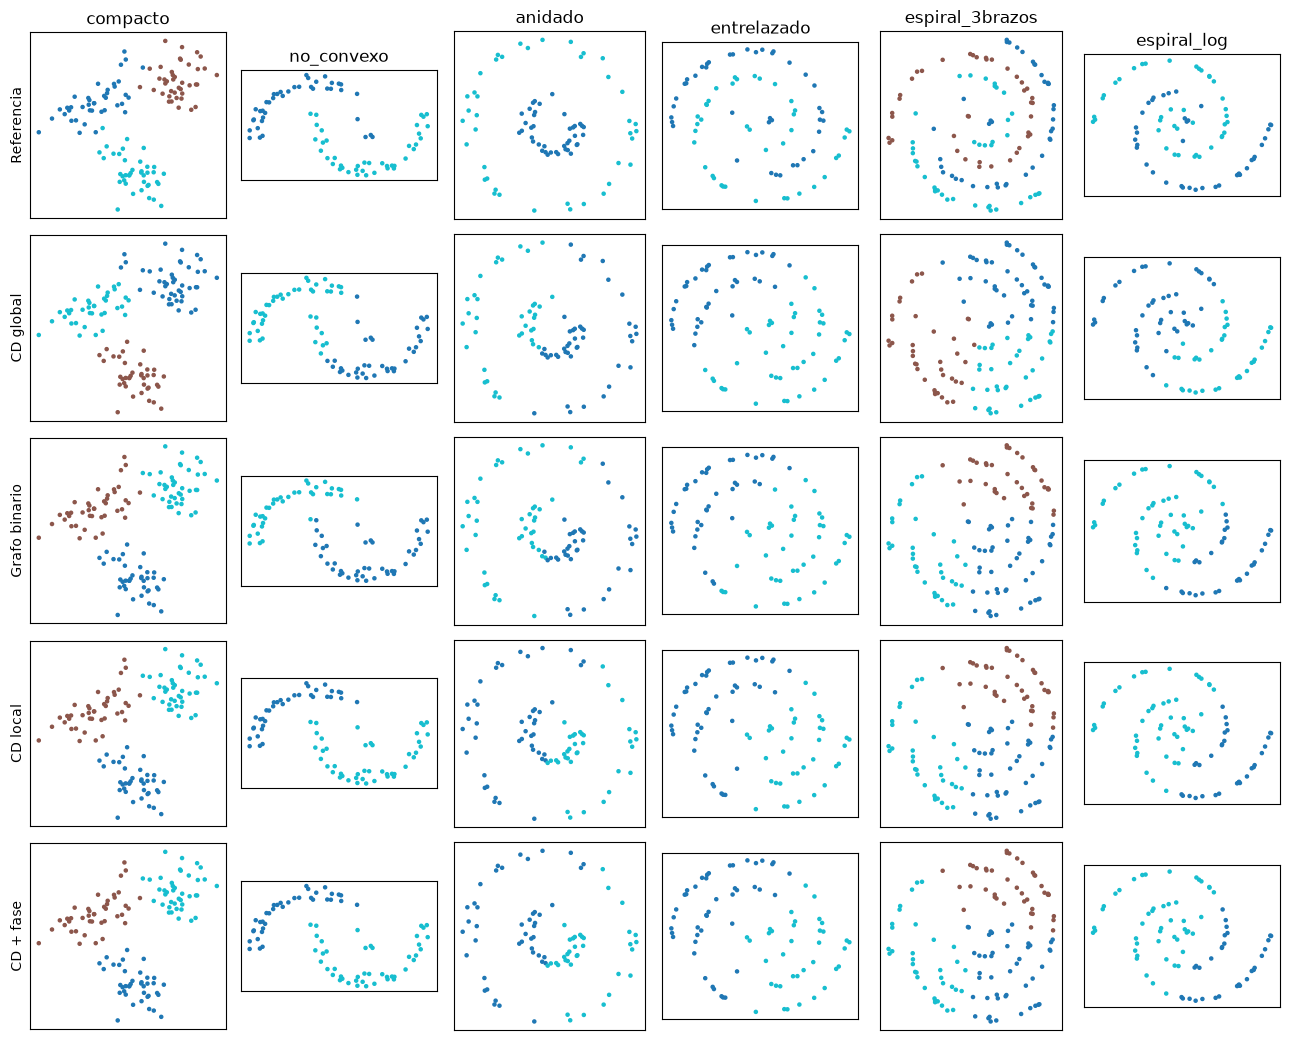

In [6]:
def fase(X,k):
    Y=normal(X);r=np.linalg.norm(Y,axis=1);theta=np.arctan2(Y[:,1],Y[:,0]);best=-np.inf
    for a in [0,*np.linspace(-12,12,25)]:
        phi=theta-a*r;F=np.c_[np.cos(phi),np.sin(phi)]
        lab=KMeans(k,n_init=3,random_state=0).fit_predict(F);s=silhouette_score(F,lab)
        if a==0:baseline=s
        if s>best:best,chosen=s,lab
    return chosen if best-baseline>.20 else spectral(grafos(X)[1],k)
bench('CD + fase',fase,True)
points=guardar('05_ARI_por_escena',pd.DataFrame(records))
display(points.pivot_table(index='caso',columns='modelo',values='ARI').round(3))
panel(['Referencia','CD global','Grafo binario','CD local','CD + fase'],'05_ablation')

## 06 · ¿Se conserva la estructura intrínseca? ¿Y se separan tres objetos en 3D?
Enrollemos las coordenadas 2D en una lámina 3D: conocemos el mapa latente para evaluar vecindades. T penaliza vecinos espurios y la continuidad penaliza vecinos perdidos. En el segundo experimento la unidad vuelve a ser la escena: medimos ARI de tres cuerpos a dos separaciones, con K dado para ambos grafos. DBSCAN debe inferir el número. Una proyección 2D de los puntos sólo sirve de ilustración.

,modelo,T,continuidad
0,PCA,0.921632,0.979896
1,KPCA,0.858681,0.936215
2,Isomap,0.994375,0.995347
3,CD local,0.936910,0.975000


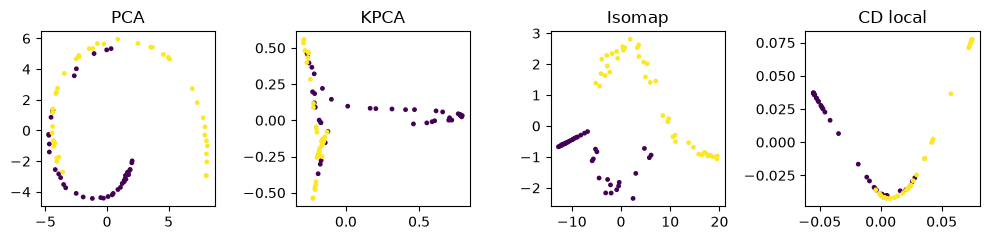

/home/icantu24/Documents/PEF-CD/point-field/.venv/lib64/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/home/icantu24/Documents/PEF-CD/point-field/.venv/lib64/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/home/icantu24/Documents/PEF-CD/point-field/.venv/lib64/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/home/icantu24/Documents/PEF-CD/point-field/.venv/lib64/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


ARI    K
separacion modelo                 
1.3        CD local  0.287608  3.0
           DBSCAN    0.002653  1.5
           espacial  0.299374  3.0
3.5        CD local  1.000000  3.0
           DBSCAN    0.967619  3.0
           espacial  1.000000  3.0

In [7]:
from sklearn.manifold import spectral_embedding
X,y=scenes['no_convexo',seeds[0]];t=2*X[:,0]+5;roll=np.c_[t*np.cos(t),X[:,1]*3,t*np.sin(t)]
emb={'PCA':PCA(2).fit_transform(roll),'KPCA':KernelPCA(2,kernel='rbf').fit_transform(roll),'Isomap':Isomap(n_neighbors=10).fit_transform(roll),'CD local':spectral_embedding(grafos(normal(roll))[1],n_components=2,random_state=0)}
display(guardar('06_vecindades',pd.DataFrame([dict(modelo=k,T=trustworthiness(X,v,n_neighbors=5),continuidad=trustworthiness(v,X,n_neighbors=5)) for k,v in emb.items()])))
fig,axs=plt.subplots(1,4,figsize=(10,2.5))
for ax,(k,v) in zip(axs,emb.items()):ax.scatter(*v.T,c=y,s=6);ax.set_title(k)
figura('06_embeddings_puntos')
res=[]
for s in seeds:
    bodies,_,_=make_object_dataset(3,1,60,families=['sphere','cube','torus'],seed=s,transform=False)
    for gap in (1.3,3.5):
        X=np.vstack([normal(x)+[i*gap,0,0] for i,x in enumerate(bodies)]);y=np.repeat(range(3),60)
        A,B=grafos(X)
        for name,l in [('espacial',spectral(A,3)),('CD local',spectral(B,3)),('DBSCAN',db(X,None))]:
            res.append(dict(seed=s,separacion=gap,modelo=name,ARI=ARI(y,l),K=len(set(l)-{-1})))
display(guardar('06_escenas3D',pd.DataFrame(res)).groupby(['separacion','modelo']).mean(numeric_only=True)[['ARI','K']])

## 07 · Pasar de un score por punto a un vector por objeto
Centrar y dividir por un único radio RMS elimina traslación y escala. En la base tensorial, las rotaciones/reflexiones preservan espectro, diagonal y correlaciones del kernel. Resumimos los dos últimos con 19 cuantiles cada uno. Agregamos 30 potencias angulares: tres ventanas radiales, seis pares de ventanas y cinco órdenes. Los controles de momentos y CD usan el mismo bloque angular. Comparamos bloques estructural y angular con el mismo peso total. El descriptor descarta orientación, incluida la quiralidad: probar invariancia no prueba discriminación.

In [8]:
qs=np.linspace(.05,.95,19)
def bloques(X):
    Y=normal(X);m=ajustar(Y);Z=blanco(m,Y);K=Z@Z.T;q=np.diag(K);ii=np.triu_indices(len(Y),1)
    corr=K[ii]/np.sqrt(q[ii[0]]*q[ii[1]])
    def spec(M):return np.log1p(np.maximum(np.linalg.eigvalsh(M),0))
    cd=np.r_[spec(m[1]),np.quantile(np.log(q/len(m[1])),qs),np.quantile(corr,qs)]
    V=base(Y,3);mom=np.r_[spec(m[1]),spec(V.T@V/len(Y))]
    r=np.linalg.norm(Y,axis=1);U=Y/np.maximum(r[:,None],1e-12);C=np.clip(U@U.T,-1,1)
    B=np.exp(-.5*((r[:,None]-[.5,1,1.5])/.4)**2);ang=[]
    for l in range(5):
        H=np.cos(l*np.arccos(C)) if Y.shape[1]==2 else eval_legendre(l,C)
        if l:H=H*np.outer(r>1e-12,r>1e-12)
        ang.extend((B.T@H@B/len(Y)**2)[np.triu_indices(3)])
    hist=np.histogram(pdist(Y),np.r_[np.linspace(0,4,33),np.inf])[0]
    # Variante W: sólo cambia la medida de M; los cuantiles y el bloque angular siguen sin pesos.
    radii=np.partition(cdist(Y,Y),16,axis=1)[:,16];med=np.median(radii)
    if med<=0:raise ValueError('Radio kNN mediano nulo; inspeccionar puntos duplicados')
    w=np.clip((radii/med)**(Y.shape[1]-1),.25,4);w/=w.sum()
    mw=ajustar(Y,w=w);Zw=blanco(mw,Y);Kw=Zw@Zw.T;qw=np.diag(Kw)
    cw=Kw[ii]/np.sqrt(qw[ii[0]]*qw[ii[1]])
    cdw=np.r_[spec(mw[1]),np.quantile(np.log(qw/len(mw[1])),qs),np.quantile(cw,qs)]
    momw=np.r_[spec(mw[1]),spec(V.T@(w[:,None]*V))]
    return {'CD W':[cdw,np.array(ang)],'Momentos W':[momw,np.array(ang)],'D2':[hist/hist.sum()],'Momentos':[mom,np.array(ang)],'CD solo':[cd],'CD + angular':[cd,np.array(ang)]}
inv=[]
for d in [2,3]:
    clouds,_,names=make_object_dataset(d,1,N,seed=SEM)
    Q,_=np.linalg.qr(rng(d).normal(size=(d,d)));Q[:,0]*=-np.sign(np.linalg.det(Q))
    for X,name in zip(clouds,names):
        f=lambda x:np.concatenate(bloques(x)['CD + angular'])
        a,b=f(X),f((2.3*X@Q+5)[::-1]);inv.append(dict(dim=d,familia=name,error=np.linalg.norm(a-b)/np.linalg.norm(a),longitud=len(a)))
inv=guardar('07_invariancia',pd.DataFrame(inv));display(inv);assert inv.error.max()<1e-8

,dim,familia,error,longitud
0,2,ellipse,1.478824e-15,74
1,2,rectangle,1.556489e-15,74
2,2,triangle,4.794135e-15,74
3,2,hexagon,1.449257e-15,74
4,2,star,2.291961e-15,74
5,2,annulus,2.946707e-15,74
6,3,sphere,9.743453e-16,78
7,3,ellipsoid,3.547363e-15,78
8,3,cube,4.160980e-15,78
9,3,cylinder,3.181061e-15,78


## 08 · ModelNet opcional: crear los datos y las particiones sin un cargador externo
Una malla OFF no es todavía una nube. Triangulamos caras en abanico (supuesto: caras triangulares o convexas), elegimos triángulos con probabilidad proporcional al área y muestreamos coordenadas baricéntricas. Se conserva la partición oficial; referencia y validación salen de train. Una identidad se define por SHA-256 de los bytes. Descartamos todos los archivos con el mismo hash y etiquetas distintas antes de seleccionar objetos. Esto no detecta dos mallas equivalentes guardadas de forma distinta. El manifiesto guarda las semillas y las rutas relativas; repetir una vista no crea un objeto independiente.

In [11]:
def off(path,n,s):
    lines=[l.split('#')[0].strip() for l in path.read_text().splitlines()];lines=[l for l in lines if l]
    if not lines[0].startswith('OFF'):raise ValueError(path)
    header=lines.pop(0)[3:].strip() or lines.pop(0);nv,nf,*_=map(int,header.split())
    v=np.array([list(map(float,l.split()[:3])) for l in lines[:nv]]);tri=[]
    if len(lines)<nv+nf or not np.isfinite(v).all():raise ValueError(path)
    for l in lines[nv:nv+nf]:
        a=l.split();ids=list(map(int,a[1:1+int(a[0])]))
        if len(ids)!=int(a[0]) or min(ids)<0 or max(ids)>=nv:raise ValueError(path)
        tri.extend((ids[0],ids[i],ids[i+1]) for i in range(1,len(ids)-1))
    a,b,c=v[np.array(tri,dtype=int)].transpose(1,0,2)
    area=np.linalg.norm(np.cross(b-a,c-a),axis=1);g=rng(s)
    if not area.sum()>0:raise ValueError(f'Malla sin área: {path}')
    i=g.choice(len(a),n,p=area/area.sum());u=np.sqrt(g.random(n));w=g.random(n)
    return (1-u[:,None])*a[i]+(u*(1-w))[:,None]*b[i]+(u*w)[:,None]*c[i]
def catalogo(name,root):
    rows=[]
    for p in sorted(root.rglob('*.off')):
        if p.parent.name in ('train','test'):
            rows.append((str(p.relative_to(root)),p.parent.parent.name,p.parent.name,hashlib.sha256(p.read_bytes()).hexdigest()))
    df=pd.DataFrame(rows,columns=['id','clase','oficial','hash'])
    expected={'ModelNet10':10,'ModelNet40':40}[name]
    if df.clase.nunique()!=expected:raise ValueError(f'{root}: se esperaban {expected} clases con archivos OFF')
    amb=df.groupby('hash').clase.transform('nunique')>1
    keep=df[~amb].sort_values(['oficial','id'],ascending=[False,True]);dup=keep.duplicated('hash')
    guardar(name+'_excluidos',pd.concat([df[amb].assign(motivo='etiquetas distintas'),keep[dup].assign(motivo='copia exacta')]))
    clean=keep[~dup];parts=[];nr,nv,nt=(3,2,2) if MODE=='rapido' else (40,10,20)
    for label in sorted(df.clase.unique()):
        g=clean[clean.clase==label];tr=g[g.oficial=='train'].sample(frac=1,random_state=sem(SEM,label));te=g[g.oficial=='test'].sample(frac=1,random_state=sem(SEM,label,'test'))
        if len(tr)<nr+nv or len(te)<nt:raise ValueError(f'{name}/{label}: train={len(tr)}, test={len(te)}; cuota insuficiente')
        for tag,sub in [('ref',tr[:nr]),('validation',tr[nr:nr+nv]),('test',te[:nt])]:parts.append(sub.assign(part=tag))
    m=pd.concat(parts);m['seed']=[sem(SEM,i) for i in m.id];assert m.hash.is_unique
    return guardar(name+'_manifiesto',m)
datasets={}; manifests={}
for d in (2,3):
    groups=[]
    for tag,count,s in [('ref',4,1),('validation',2,2),('test',3,3)]:
        count=count if MODE=='rapido' else {'ref':30,'validation':10,'test':20}[tag]
        X,y,names=make_object_dataset(d,count,N,seed=SEM+s);groups.append((X,np.array(names)[y],np.array([f'{tag}-{i}' for i in range(len(y))])))
    datasets[f'PF{d}D']=dict(zip(['ref','validation','test'],groups))
if REAL:
    for name,root in ROOTS.items():
        if root is None:continue
        m=catalogo(name,root);manifests[name]=m;datasets[name]={}
        for tag in dict.fromkeys(['ref','validation',PART]):
            g=m[m.part==tag];datasets[name][tag]=([off(root/i,N,s) for i,s in zip(g.id,g.seed)],g.clase.to_numpy(),g.id.to_numpy())
    if len(manifests)==2:
        a,b=manifests.values();guardar('ModelNet_solapamientos',a.merge(b,on='hash',suffixes=('_10','_40')))
print('Datasets disponibles:',list(datasets))

Datasets disponibles: ['PF2D', 'PF3D']


## 09 · Benchmark de objetos y mejora multivista
Primero se evalúan D2, momentos, CD solo y CD con bloque angular. A continuación, sin cambiar las consultas, se estima una distancia que penaliza menos las direcciones sensibles al remuestreo: C=media(ΔΔᵀ), Δ=vista−original. Se usa (C+α tr(C)/p I)⁻¹ con α=1 fijado antes de evaluar; es una variante docente. Momentos recibe la misma adaptación. Las variantes W ponderan la matriz por la distancia al vecino 16 elevada a d−1, recortada entre 0.25 y 4 tras dividir por la mediana. La hipótesis d−1 corresponde a superficies; los objetos volumétricos permiten ver sus límites. Comparar CD W MV con CD + angular MV prueba el aporte de la ponderación, no el de la métrica. El ajuste de escalas, covarianzas y galerías usa exclusivamente referencia. mAP mide el ranking completo; 1-NN sólo su primer elemento. ARI/AMI se calculan agrupando objetos de consulta con K conocido. Las clases sirven para puntuar, no para ajustar descriptores.

,dataset,modelo,mAP,1NN,ARI,AMI
0,PF2D,CD + angular,0.729361,0.777778,0.400564,0.543471
1,PF2D,CD + angular MV,0.872207,0.888889,0.400564,0.543471
2,PF2D,CD W,0.743850,0.777778,0.400564,0.543471
3,PF2D,CD W MV,0.863360,0.888889,0.400564,0.543471
4,PF2D,CD solo,0.852367,1.000000,0.332265,0.407598
5,PF2D,D2,0.626929,0.611111,0.046970,0.112037
6,PF2D,Momentos,0.729508,0.833333,0.400564,0.543471
7,PF2D,Momentos MV,0.821012,0.944444,0.400564,0.543471
8,PF2D,Momentos W,0.729625,0.833333,0.400564,0.543471
9,PF2D,Momentos W MV,0.837956,0.888889,0.400564,0.543471


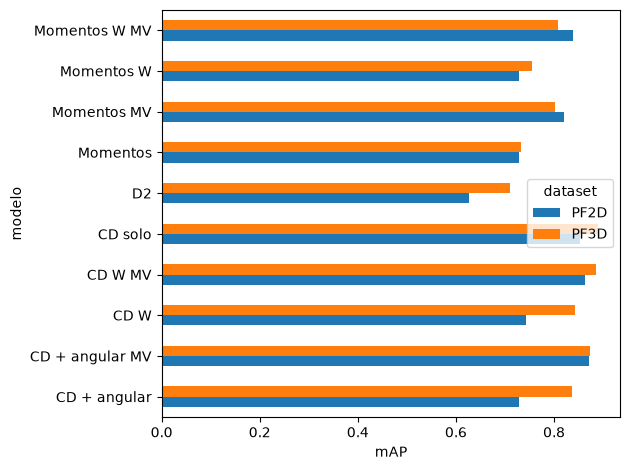

In [12]:
def view(X,s,cond):
    g=rng(s);Y=normal(X);u=g.normal(size=X.shape[1]);t=Y@(u/np.linalg.norm(u));n=len(X)
    if cond=='densidad':
        p=np.exp(2*np.clip(t,-2,2));return X[g.choice(n,n//2,False,p=p/p.sum())]
    if cond=='mitad':return X[g.choice(n,n//2,False)]
    if cond=='oclusion':return X[t<=np.quantile(t,.8)]
    r=np.sqrt(((X-X.mean(0))**2).sum(1).mean())
    if cond=='ruido':return X+.03*r*g.normal(size=X.shape)
    if cond=='atipicos':return np.vstack([X,X.mean(0)+r*g.uniform(-5,5,(max(1,n//20),X.shape[1]))])
    return X
def matriz(fs,k):return np.array([np.concatenate(v[k]) for v in fs])
def fit(R):
    fs=list(map(bloques,R));vs=[bloques(view(x,sem(SEM,i,'fit'),'densidad')) for i,x in enumerate(R)];mods={}
    for k in fs[0]:
        F=matriz(fs,k);mu=F.mean(0);sizes=[len(b) for b in fs[0][k]]
        sd=np.maximum(F.std(0),1e-6)*np.repeat(np.sqrt(sizes),sizes)*np.sqrt(len(sizes));G=(F-mu)/sd
        mods[k]=(k,mu,sd,None,G)
        if k in ('Momentos','CD + angular','CD W','Momentos W'):
            delta=(matriz(vs,k)-F)/sd;C=delta.T@delta/len(R);ev,U=np.linalg.eigh(C)
            W=(U/np.sqrt(np.maximum(ev,0)+max(np.trace(C)/len(C),1e-10)))@U.T
            mods[k+' MV']=(k,mu,sd,W,G@W)
    return mods
def transformar(mods,X):
    fs=list(map(bloques,X));result={}
    for name,(k,mu,sd,W,G) in mods.items():
        A=(matriz(fs,k)-mu)/sd;result[name]=A if W is None else A@W
    return result
def evaluar(mods,Z,yr,yq,ids,ds,cond,rep):
    rows=[];cl=[]
    for name,F in Z.items():
        G=mods[name][-1];order=np.argsort(cdist(F,G),axis=1,kind='stable')
        rel=(yr[order]==yq[:,None]);assert (rel.sum(1)>0).all()
        ap=((rel.cumsum(1)/np.arange(1,len(G)+1))*rel).sum(1)/rel.sum(1)
        rows.extend(dict(dataset=ds,cond=cond,rep=rep,modelo=name,id=i,clase=y,AP=a,acierto=int(hit)) for i,y,a,hit in zip(ids,yq,ap,rel[:,0]))
        for s in seeds:
            lab=KMeans(len(set(yq)),n_init=10,random_state=s).fit_predict(F)
            cl.append(dict(dataset=ds,cond=cond,rep=rep,modelo=name,seed=s,ARI=ARI(yq,lab),AMI=AMI(yq,lab)))
    return rows,cl
cache={};rows=[];clusters=[]
for ds,groups in datasets.items():
    R,yr,_=groups['ref'];Q,yq,ids=groups[PART if ds.startswith('ModelNet') else 'test']
    mods=fit(R);Z=transformar(mods,Q);cache[ds]=(mods,Z,Q,yq,ids)
    a,b=evaluar(mods,Z,yr,yq,ids,ds,'limpio',0);rows+=a;clusters+=b
raw=pd.DataFrame(rows);cl=pd.DataFrame(clusters)
report=raw.groupby(['dataset','modelo'])[['AP','acierto']].mean().join(cl.groupby(['dataset','modelo'])[['ARI','AMI']].mean()).rename(columns={'AP':'mAP','acierto':'1NN'})
display(guardar('09_objetos_limpios',report.reset_index()))
report.mAP.unstack(0).plot.barh();plt.xlabel('mAP');figura('09_recuperacion')

## 10 · Robustez: medir qué cambia y atribuir la diferencia
Los modelos anteriores permanecen congelados. Todos reciben la misma realización por objeto y condición. El control «mitad» conserva el mismo N que el sesgo direccional: así se distingue el efecto de perder puntos del efecto de dónde se pierden. El bootstrap remuestrea objetos dentro de clase después de promediar repeticiones, manteniendo el emparejamiento CD−momentos; condiciona la inferencia a la galería y el ajuste actuales.

,dataset,cond,delta,inferior,superior
0,PF2D,atipicos,-0.041695,-0.082382,-0.005484
1,PF2D,densidad,0.090988,-0.004426,0.220174
2,PF2D,limpio,0.051196,-0.000191,0.113824
3,PF2D,mitad,0.012385,-0.078264,0.082199
4,PF2D,oclusion,0.151425,0.063331,0.244491
5,PF2D,ruido,0.016218,-0.012908,0.056005
6,PF3D,atipicos,0.003739,-0.020707,0.032677
7,PF3D,densidad,0.034457,-0.016305,0.080242
8,PF3D,limpio,0.071402,0.027777,0.118323
9,PF3D,mitad,0.039473,0.002176,0.093031


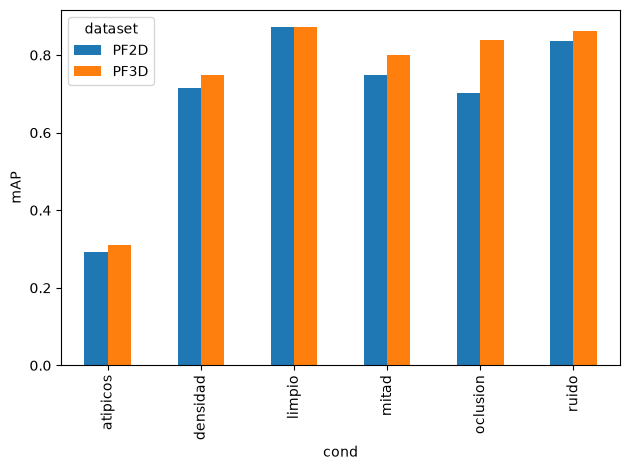

In [13]:
for ds,(mods,Z,Q,yq,ids) in cache.items():
    for cond in ['mitad','densidad','ruido','oclusion','atipicos']:
        for rep in range(1 if MODE=='rapido' else 3):
            P=[view(x,sem(SEM,ds,i,rep,cond),cond) for i,x in zip(ids,Q)]
            a,b=evaluar(mods,transformar(mods,P),datasets[ds]['ref'][1],yq,ids,ds,cond,rep);rows+=a;clusters+=b
raw=guardar('10_AP_por_objeto',pd.DataFrame(rows));guardar('10_particiones_por_semilla',pd.DataFrame(clusters))
wide=raw.pivot_table(index=['dataset','cond','clase','id'],columns='modelo',values='AP')
ci=[]
for (ds,cond),g in wide.groupby(level=['dataset','cond']):
    diff=g['CD + angular MV']-g['Momentos MV'];groups=[v.to_numpy() for _,v in diff.groupby(level='clase')]
    gen=rng(sem(ds,cond));bs=[np.concatenate([gen.choice(v,len(v)) for v in groups]).mean() for _ in range(200 if MODE=='rapido' else 3000)]
    ci.append(dict(dataset=ds,cond=cond,delta=diff.mean(),inferior=np.quantile(bs,.025),superior=np.quantile(bs,.975)))
ci=guardar('10_contraste_pareado',pd.DataFrame(ci));display(ci)
wide['CD + angular MV'].groupby(level=['dataset','cond']).mean().unstack(0).plot.bar();plt.ylabel('mAP');figura('10_robustez')

## 11 · ¿Qué geometría se puede reconstruir desde el embedding?
En entrenamiento, cada vector se empareja con un histograma de ocupación en pose PCA. Se ajusta una regresión ridge del vector al campo, sin etiquetas. La pose se fija con ejes principales y signos de terceros momentos: es ambigua en figuras simétricas. En validación se elige α por Hellinger². El decoder nunca usa la nube objetivo para predecir su campo; la nube sí se usa al puntuarlo. La media de referencia ignora el vector; el oráculo de rejilla usa el objetivo y cuantifica el error de discretización/muestreo. ModelNet necesita test habilitado para no puntuar sobre la misma validación usada al elegir α.

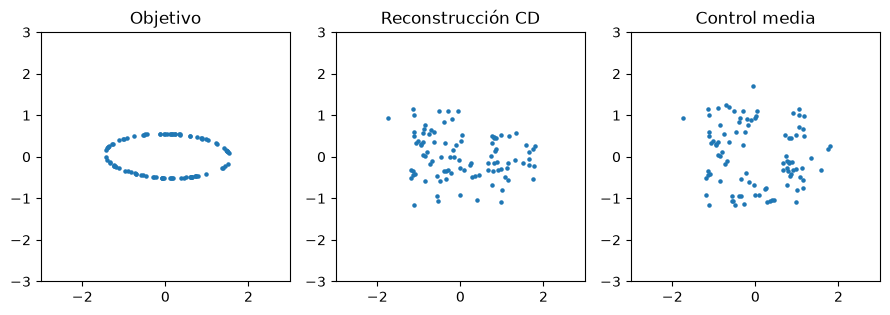

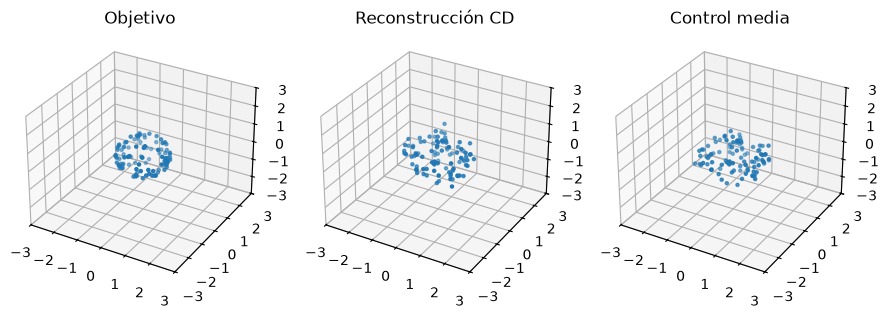

H2  Chamfer2
dataset modelo                             
PF2D    CD + angular     0.088880  0.044503
        CD + angular MV  0.098085  0.045421
        CD W             0.089236  0.044375
        CD W MV          0.097476  0.044798
        CD solo          0.103145  0.045341
        D2               0.129499  0.057551
        Media            0.143848  0.055100
        Momentos         0.086034  0.044417
        Momentos MV      0.099451  0.045003
        Momentos W       0.087570  0.043740
        Momentos W MV    0.086041  0.044285
        Oráculo rejilla  0.000000  0.033914
PF3D    CD + angular     0.146438  0.101781
        CD + angular MV  0.146888  0.099716
        CD W             0.146473  0.101407
        CD W MV          0.146685  0.099749
        CD solo          0.147910  0.098087
        D2               0.155213  0.100044
        Media            0.186107  0.111585
        Momentos         0.145679  0.102510
        Momentos MV      0.144371  0.100880
        Momentos W       0.147249  0.101192
        Momentos W MV    0.146299  0.100431
        Oráculo rejilla  0.000000  0.074533

In [14]:
def campo(x,b=10):
    Y=normal(x);_,U=np.linalg.eigh(Y.T@Y);z=Y@U[:,::-1];z*=np.where((z**3).mean(0)<0,-1,1)
    h=np.histogramdd(z,bins=b,range=[(-3,3)]*z.shape[1])[0].ravel()
    if not h.sum():raise ValueError('Campo vacío')
    return h/h.sum(),z
def puntos(p,d,s,b=10):
    g=rng(s);idx=g.choice(len(p),N,p=p);ij=np.array(np.unravel_index(idx,(b,)*d)).T
    return -3+(ij+g.random(ij.shape))*6/b
def hell(p,h):return .5*((np.sqrt(p)-np.sqrt(h))**2).sum(-1)
rr=[]
for ds,(mods,Z,Q,yq,ids) in cache.items():
    if ds.startswith('ModelNet') and PART!='test':continue
    R=datasets[ds]['ref'][0];V=datasets[ds]['validation'][0];Zv=transformar(mods,V)
    H=np.array([campo(x)[0] for x in R]);Hv=np.array([campo(x)[0] for x in V]);targets=[campo(x) for x in Q];Hq=np.array([h for h,z in targets])
    preds={'Media':(np.tile(H.mean(0),(len(Q),1)),None),'Oráculo rejilla':(Hq,None)}
    for name in mods:
        G=mods[name][-1];A=G-G.mean(0);mu=H.mean(0);best=np.inf
        for alpha in [.1,1.,10.]:
            W=np.linalg.solve(A.T@A+alpha*np.eye(A.shape[1]),A.T@(H-mu))
            def dec(F):
                P=np.maximum((F-G.mean(0))@W+mu,0);P[P.sum(1)==0]=mu;return P/P.sum(1,keepdims=True)
            loss=hell(dec(Zv[name]),Hv).mean()
            if loss<best:best=loss;preds[name]=(dec(Z[name]),alpha)
    for name,(P,alpha) in preds.items():
        for i,(p,(h,z)) in enumerate(zip(P,targets)):
            x=puntos(p,z.shape[1],sem(ds,i));D=cdist(x,z,'sqeuclidean')
            rr.append(dict(dataset=ds,modelo=name,id=ids[i],alpha=alpha,H2=hell(p,h),Chamfer2=.5*(D.min(0).mean()+D.min(1).mean())))
    d=Q[0].shape[1];fig=plt.figure(figsize=(9,3))
    for i,(title,x) in enumerate([('Objetivo',targets[0][1]),('Reconstrucción CD',puntos(preds['CD + angular MV'][0][0],d,sem(ds,0))),('Control media',puntos(preds['Media'][0][0],d,sem(ds,0)))]):
        ax=fig.add_subplot(1,3,i+1,projection='3d' if d==3 else None);ax.scatter(*x.T,s=5);ax.set(xlim=(-3,3),ylim=(-3,3),title=title)
        if d==3:ax.set_zlim(-3,3)
        else:ax.set_aspect('equal')
    figura('11_reconstruccion_'+ds)
rec=guardar('11_decoder_por_objeto',pd.DataFrame(rr));display(rec.groupby(['dataset','modelo'])[['H2','Chamfer2']].mean())

## 12 · Del cuaderno al texto de la tesis
Para una tabla de recuperación, elige un dataset y condición, agrupa AP por objeto y luego promedia objetos. Para atribuir una mejora de afinidad, compara CD local con el grafo binario en la misma escena y semilla. Para atribuirla al descriptor, contrasta CD con momentos usando la misma métrica. Para reconstrucción, una reducción respecto a la media indica información útil para ese decoder; no implica inversión única. Se muestran abajo resultados calculados, no conclusiones escritas de antemano.

**Alcance:** la ejecución rápida comprueba el flujo. El modo amplio no replica los splits históricos ni todos sus algoritmos. No se evalúan ShapeNet, CD-barrera histórico, POD/SVD como compresor, redes profundas ni un método CD que descubra K en escenas. DBSCAN sí estima K. Para un resultado publicable conserva los manifiestos, la notebook ejecutada y la configuración, registra recursos y evita afinar métodos mirando test.

In [15]:
print('Origen de cada valor: tabla 05 = media por escena y semilla; 09 = AP/aciertos por objeto y ARI/AMI por partición; 10 = diferencias pareadas; 11 = errores por objeto.')
display(ci[ci.cond.isin(['limpio','densidad'])].round(4))
print('ModelNet ejecutado:',list(manifests) or 'ninguno (REAL=False)');print('Archivos CSV y figuras:',out)


Origen de cada valor: tabla 05 = media por escena y semilla; 09 = AP/aciertos por objeto y ARI/AMI por partición; 10 = diferencias pareadas; 11 = errores por objeto.


,dataset,cond,delta,inferior,superior
1,PF2D,densidad,0.0910,-0.0044,0.2202
2,PF2D,limpio,0.0512,-0.0002,0.1138
7,PF3D,densidad,0.0345,-0.0163,0.0802
8,PF3D,limpio,0.0714,0.0278,0.1183


ModelNet ejecutado: ninguno (REAL=False)
Archivos CSV y figuras: /home/icantu24/Documents/PEF-CD/point-field/notebooks/runs_desde_cero/20261119T212430343107Z
